# 01 · Exploración inicial del dataset ASL Alphabet

**Objetivo.** Conocer la estructura y calidad de los archivos antes de decidir cómo cargarlos o entrenar un modelo. Este notebook no modifica ni mueve el dataset.

Se exploran las imágenes de entrenamiento y, si se detecta, el conjunto de prueba. Las rutas se construyen desde la raíz del repositorio; si guardaste los datos en otro lugar, cambia `DATA_DIR` en la siguiente celda. Ejecuta las celdas en orden y conserva las salidas con los resultados que realmente obtengas.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import random

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError

# Busca la raíz del proyecto aunque el kernel se haya abierto desde notebooks/.
_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_here, *_here.parents] if (p / "notebooks").is_dir() and (p / "data").is_dir()), _here)
DATA_DIR = PROJECT_ROOT / "data" / "raw"  # Cámbialo si guardaste el dataset en otro sitio.
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}

print(f"Raíz del proyecto: {PROJECT_ROOT}")
print(f"Ruta de datos:     {DATA_DIR}")
if not DATA_DIR.exists():
    raise FileNotFoundError(f"No existe la ruta de datos: {DATA_DIR}. Ajusta DATA_DIR.")

Raíz del proyecto: C:\SOFIA\ESTUDIOS\UNIVERSIDADES\UIS\PROYECTOS GITHUB\asl-sign-language-recognition
Ruta de datos:     C:\SOFIA\ESTUDIOS\UNIVERSIDADES\UIS\PROYECTOS GITHUB\asl-sign-language-recognition\data\raw


## 1. Estructura de carpetas

Primero listamos carpetas y cantidades de archivos de imagen. Esto ayuda a comprobar cómo quedó extraído el archivo descargado.

In [2]:
def image_files(folder: Path):
    """Devuelve imágenes bajo una carpeta, ordenadas para resultados reproducibles."""
    return sorted(p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)

for folder in sorted(p for p in DATA_DIR.rglob("*") if p.is_dir()):
    depth = len(folder.relative_to(DATA_DIR).parts)
    if depth <= 4:
        direct_images = sum(1 for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
        child_dirs = sum(1 for p in folder.iterdir() if p.is_dir())
        print(f"{'  ' * (depth - 1)}{folder.relative_to(DATA_DIR)}  [subcarpetas: {child_dirs}, imágenes directas: {direct_images}]")

root_images = image_files(DATA_DIR)
print(f"\nTotal de archivos con extensión de imagen: {len(root_images):,}")

asl_alphabet_test  [subcarpetas: 1, imágenes directas: 0]
  asl_alphabet_test\asl_alphabet_test  [subcarpetas: 0, imágenes directas: 28]
asl_alphabet_train  [subcarpetas: 1, imágenes directas: 0]
  asl_alphabet_train\asl_alphabet_train  [subcarpetas: 29, imágenes directas: 0]
    asl_alphabet_train\asl_alphabet_train\A  [subcarpetas: 0, imágenes directas: 3000]
    asl_alphabet_train\asl_alphabet_train\B  [subcarpetas: 0, imágenes directas: 3000]
    asl_alphabet_train\asl_alphabet_train\C  [subcarpetas: 0, imágenes directas: 3000]
    asl_alphabet_train\asl_alphabet_train\D  [subcarpetas: 0, imágenes directas: 3000]
    asl_alphabet_train\asl_alphabet_train\del  [subcarpetas: 0, imágenes directas: 3000]
    asl_alphabet_train\asl_alphabet_train\E  [subcarpetas: 0, imágenes directas: 3000]
    asl_alphabet_train\asl_alphabet_train\F  [subcarpetas: 0, imágenes directas: 3000]
    asl_alphabet_train\asl_alphabet_train\G  [subcarpetas: 0, imágenes directas: 3000]
    asl_alphabet_train\as

## 2. Detección de clases y conteo

Buscamos carpetas cuyos subdirectorios contengan imágenes directamente. La candidata con más subdirectorios de clase se toma como raíz de entrenamiento. La detección es una ayuda para inspeccionar; revisa la salida antes de usarla en el pipeline.

In [3]:
def find_class_root(base: Path):
    candidates = []
    for parent in [base, *(p for p in base.rglob("*") if p.is_dir())]:
        class_dirs = [d for d in parent.iterdir() if d.is_dir() and any(
            f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS for f in d.iterdir()
        )]
        if class_dirs:
            total = sum(sum(1 for f in d.iterdir() if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS) for d in class_dirs)
            candidates.append((len(class_dirs), total, parent, class_dirs))
    if not candidates:
        return None, []
    _, _, parent, class_dirs = max(candidates, key=lambda item: (item[0], item[1]))
    return parent, sorted(class_dirs)

CLASS_ROOT, CLASS_DIRS = find_class_root(DATA_DIR)
if CLASS_ROOT is None:
    print("No se encontró una estructura de carpetas por clase.")
    class_counts = pd.DataFrame(columns=["clase", "cantidad"])
else:
    print(f"Raíz de clases detectada: {CLASS_ROOT.relative_to(PROJECT_ROOT)}")
    class_counts = pd.DataFrame([
        {"clase": folder.name, "cantidad": sum(1 for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)}
        for folder in CLASS_DIRS
    ]).sort_values("clase", ignore_index=True)
    display(class_counts)
    print(f"Clases detectadas: {len(class_counts)} | Imágenes en carpetas de clase: {class_counts['cantidad'].sum():,}")

Raíz de clases detectada: data\raw\asl_alphabet_train\asl_alphabet_train


,clase,cantidad
0,A,3000
1,B,3000
2,C,3000
3,D,3000
4,E,3000
5,F,3000
6,G,3000
7,H,3000
8,I,3000
9,J,3000


Clases detectadas: 29 | Imágenes en carpetas de clase: 87,000


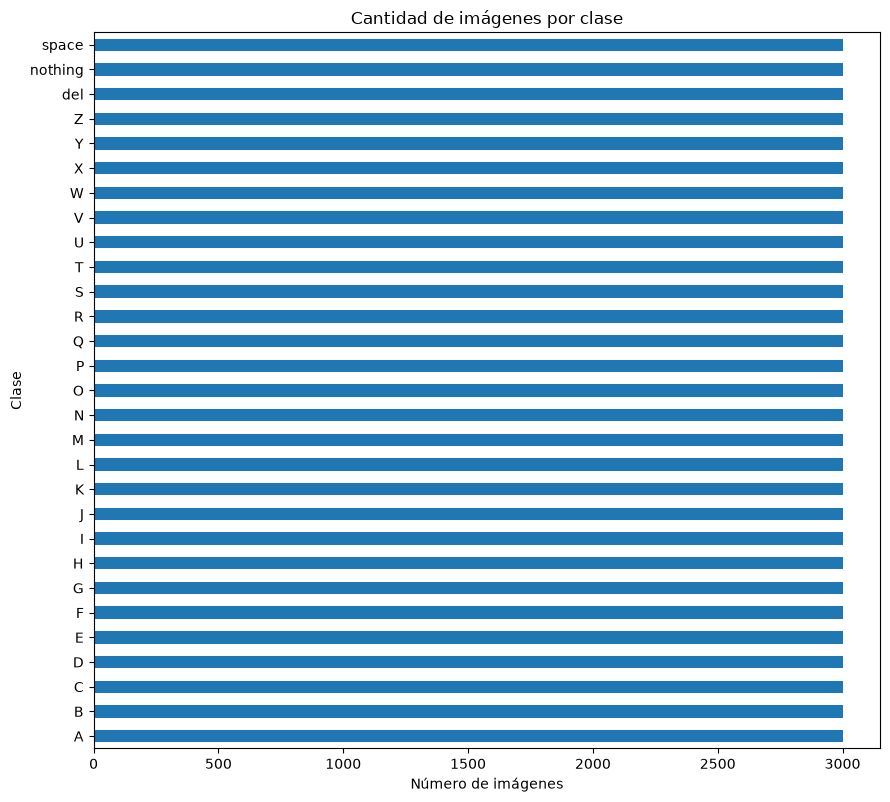

Resumen de cantidades por clase:


,count,mean,std,min,25%,50%,75%,max
cantidad,29.0,3000.0,0.0,3000.0,3000.0,3000.0,3000.0,3000.0


In [4]:
if not class_counts.empty:
    ax = class_counts.sort_values("cantidad").plot.barh(x="clase", y="cantidad", figsize=(9, max(6, 0.28 * len(class_counts))), legend=False)
    ax.set(title="Cantidad de imágenes por clase", xlabel="Número de imágenes", ylabel="Clase")
    plt.tight_layout()
    plt.show()
    print("Resumen de cantidades por clase:")
    display(class_counts["cantidad"].describe().to_frame().T)

## 3. Formato, dimensiones y canales

Revisamos todas las imágenes para resumir formato, dimensiones y modo de color. Si un archivo no se puede abrir, se registra como posible archivo corrupto. Esta lectura puede tardar un poco porque recorre el dataset completo.

In [5]:
records = []
corrupt_files = []
for path in root_images:
    try:
        with Image.open(path) as img:
            records.append({
                "ruta": str(path.relative_to(DATA_DIR)),
                "formato": img.format,
                "ancho": img.width,
                "alto": img.height,
                "modo_color": img.mode,
                "clase": path.parent.name if CLASS_ROOT and CLASS_ROOT in path.parents else None,
            })
            img.verify()
    except (OSError, ValueError, UnidentifiedImageError) as exc:
        corrupt_files.append({"ruta": str(path.relative_to(DATA_DIR)), "error": str(exc)})

image_info = pd.DataFrame(records)
corrupt_df = pd.DataFrame(corrupt_files)
print(f"Imágenes legibles: {len(image_info):,} | Archivos con error: {len(corrupt_df):,}")
if not image_info.empty:
    print("Formatos:")
    display(image_info["formato"].value_counts(dropna=False).rename_axis("formato").to_frame("cantidad"))
    print("Modos de color:")
    display(image_info["modo_color"].value_counts(dropna=False).rename_axis("modo").to_frame("cantidad"))
    print("Dimensiones más frecuentes:")
    display(image_info.groupby(["ancho", "alto"], dropna=False).size().sort_values(ascending=False).head(15).rename("cantidad").to_frame())
if not corrupt_df.empty:
    display(corrupt_df.head(20))

Imágenes legibles: 87,028 | Archivos con error: 0
Formatos:


,cantidad
formato,
JPEG,87028


Modos de color:


,cantidad
modo,
RGB,87028


Dimensiones más frecuentes:


,,cantidad
ancho,alto,
200,200,87028


## 4. Ejemplos representativos

Mostramos una imagen de cada clase detectada. La figura permite revisar visualmente etiquetas, encuadre, fondos, iluminación y variación entre ejemplos.

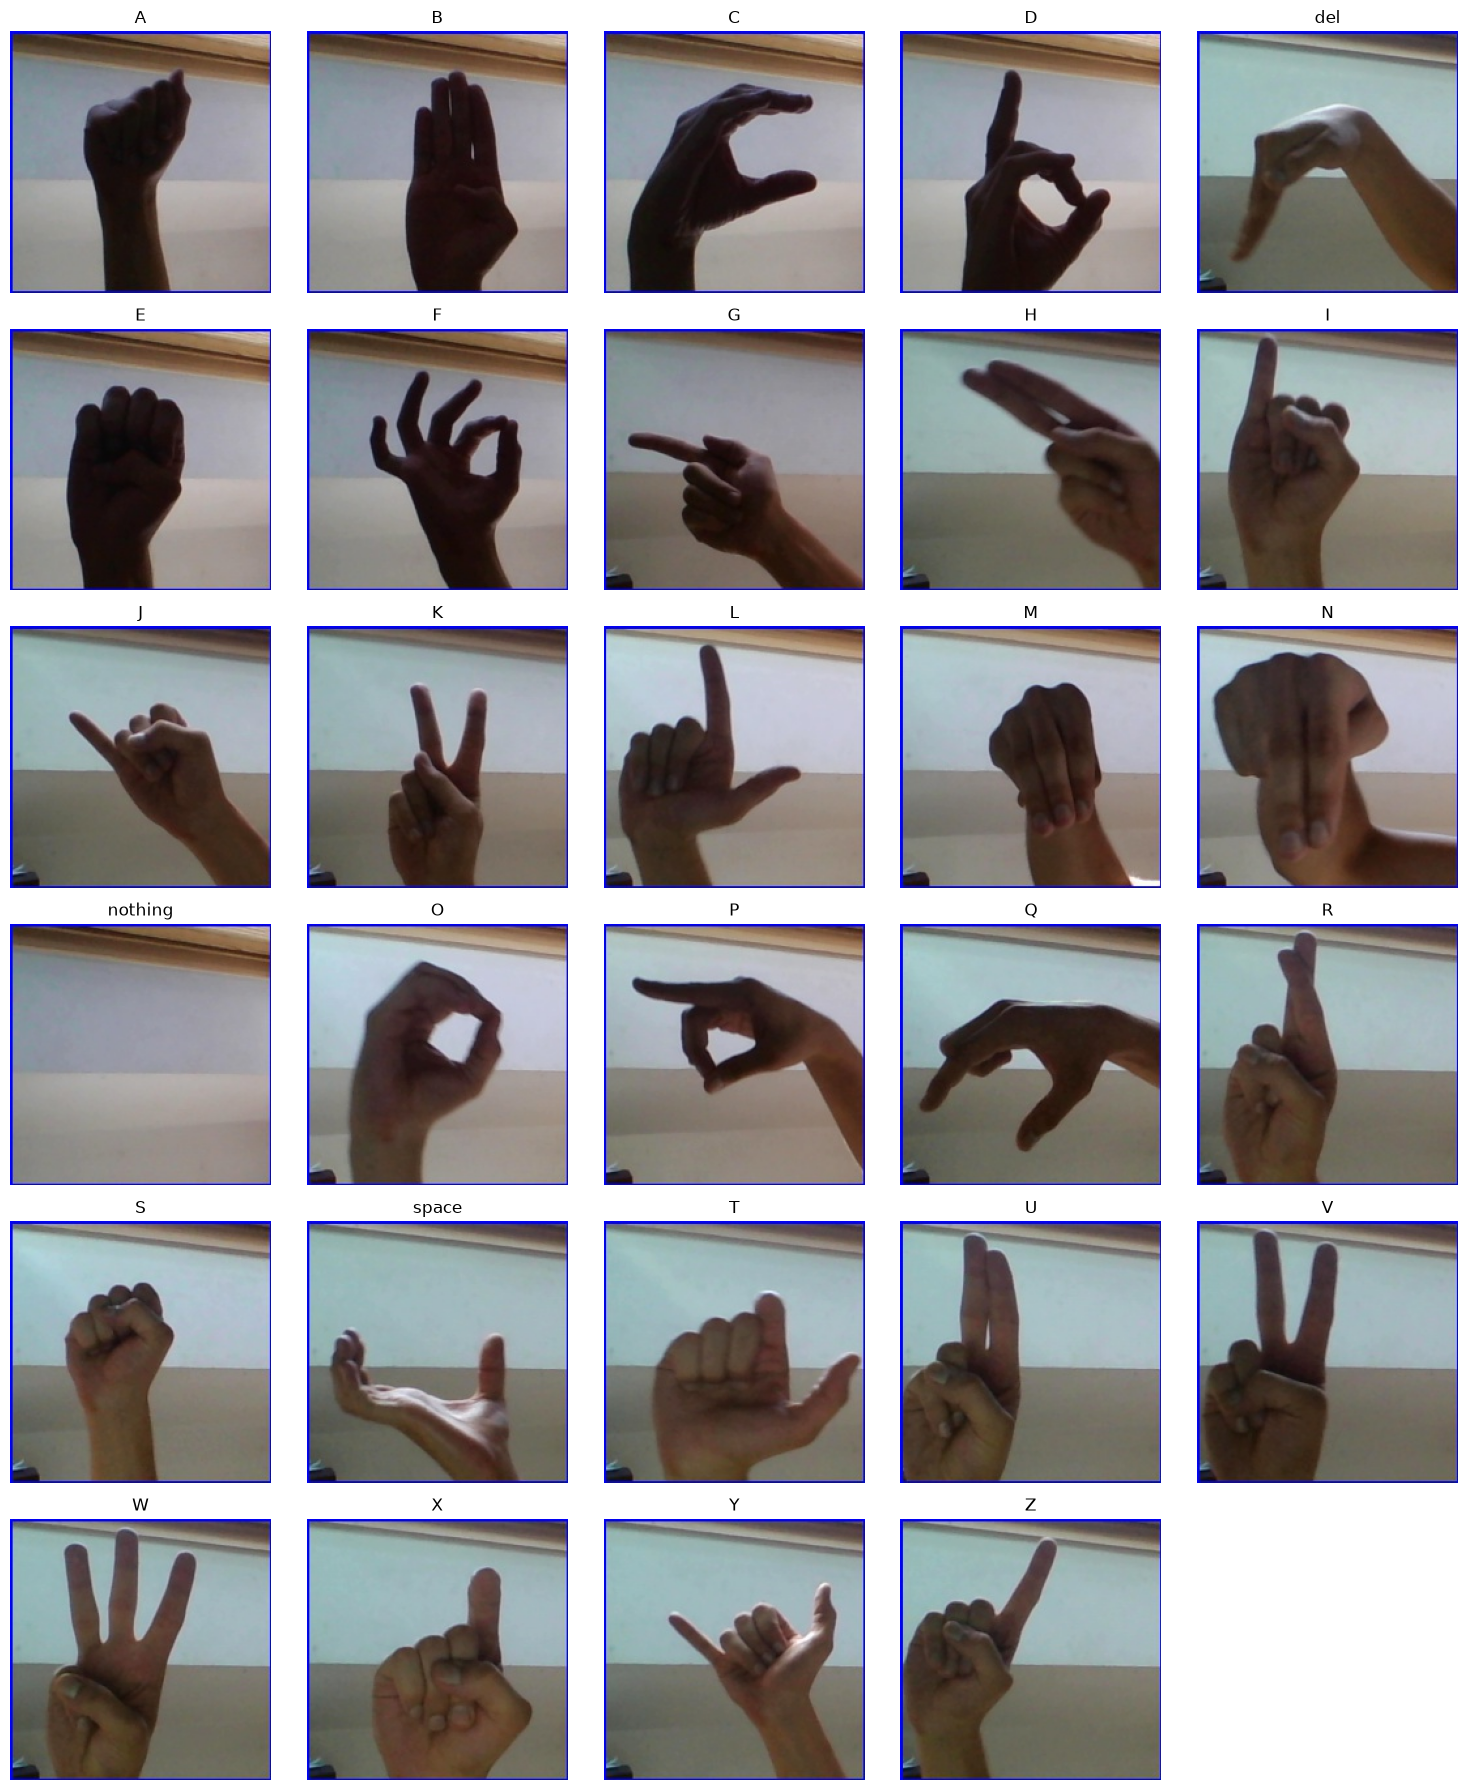

In [6]:
if CLASS_DIRS:
    ncols = 5
    nrows = (len(CLASS_DIRS) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]
    for ax, class_dir in zip(axes, CLASS_DIRS):
        candidates = image_files(class_dir)
        ax.axis("off")
        if candidates:
            with Image.open(candidates[0]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(class_dir.name)
    for ax in axes[len(CLASS_DIRS):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No hay clases en carpetas para visualizar. Revisa la estructura detectada arriba.")

## 5. Duplicados exactos

Calculamos SHA-256 para identificar copias idénticas byte a byte. Esto no detecta imágenes visualmente parecidas que tengan distinto tamaño, compresión o pequeñas modificaciones; esas requieren una comparación perceptual posterior. El análisis lee todos los archivos y puede tardar.

In [7]:
hash_to_paths = {}
for path in root_images:
    try:
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        hash_to_paths.setdefault(digest, []).append(path.relative_to(DATA_DIR).as_posix())
    except OSError as exc:
        print(f"No se pudo calcular hash para {path}: {exc}")

exact_duplicates = {digest: paths for digest, paths in hash_to_paths.items() if len(paths) > 1}
print(f"Grupos de duplicados exactos: {len(exact_duplicates)}")
if exact_duplicates:
    for paths in list(exact_duplicates.values())[:20]:
        print(" - " + " | ".join(paths))
else:
    print("No se encontraron duplicados exactos por SHA-256.")

Grupos de duplicados exactos: 28
 - asl_alphabet_test/asl_alphabet_test/A_test.jpg | asl_alphabet_train/asl_alphabet_train/A/A2995.jpg
 - asl_alphabet_test/asl_alphabet_test/B_test.jpg | asl_alphabet_train/asl_alphabet_train/B/B1.jpg
 - asl_alphabet_test/asl_alphabet_test/C_test.jpg | asl_alphabet_train/asl_alphabet_train/C/C1.jpg
 - asl_alphabet_test/asl_alphabet_test/D_test.jpg | asl_alphabet_train/asl_alphabet_train/D/D1.jpg
 - asl_alphabet_test/asl_alphabet_test/E_test.jpg | asl_alphabet_train/asl_alphabet_train/E/E1.jpg
 - asl_alphabet_test/asl_alphabet_test/F_test.jpg | asl_alphabet_train/asl_alphabet_train/F/F1.jpg
 - asl_alphabet_test/asl_alphabet_test/G_test.jpg | asl_alphabet_train/asl_alphabet_train/G/G1.jpg
 - asl_alphabet_test/asl_alphabet_test/H_test.jpg | asl_alphabet_train/asl_alphabet_train/H/H1.jpg
 - asl_alphabet_test/asl_alphabet_test/I_test.jpg | asl_alphabet_train/asl_alphabet_train/I/I1.jpg
 - asl_alphabet_test/asl_alphabet_test/J_test.jpg | asl_alphabet_train/as

## 6. Observaciones

### Estructura y distribución

- El entrenamiento está en `data/raw/asl_alphabet_train/asl_alphabet_train/`, con una carpeta por clase.
- Se detectaron **29 clases**: A–Z, `del`, `nothing` y `space`.
- Hay **3.000 imágenes por clase** (87.000 en total); la distribución está equilibrada.
- El test descargado está en `data/raw/asl_alphabet_test/asl_alphabet_test/` y contiene **28 imágenes**, con nombres de A–Z, `nothing` y `space`; no tiene una imagen `del_test.jpg`.

### Formato y calidad

- Las **87.028 imágenes** encontradas se pudieron leer: son JPEG, RGB y de 200 × 200 píxeles.
- No se encontraron archivos corruptos o ilegibles.
- La inspección SHA-256 detectó **28 grupos de duplicados exactos**: cada imagen del test descargado coincide con una imagen de entrenamiento.
- No se ejecutó una búsqueda perceptual de imágenes parecidas que no sean idénticas; la similitud visual entre imágenes queda pendiente de un análisis específico.

### Decisiones para continuar

- No usar el test descargado de Kaggle para medir desempeño, porque sus imágenes ya aparecen en entrenamiento.
- En el notebook 02, crear particiones nuevas desde las imágenes de la carpeta de entrenamiento y comprobar que no compartan archivos idénticos.
- Revisar visualmente la cuadrícula de ejemplos por clase al interpretar el dataset; los conteos y hashes no evalúan por sí solos la calidad semántica de cada etiqueta.